In [ ]:
import pandas as pd

#visualizaciones
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
#traigo archivos
df_bajas_agosto = pd.read_csv("../files/processed/bajas_agosto_2019.csv")
df_altas_agosto = pd.read_csv("../files/processed/altas_agosto_2019.csv")
df_plantilla_julio = pd.read_csv("../files/processed/plantilla_julio_2019.csv")

C:\Users\sarag\AppData\Local\Temp\ipykernel_19684\3716998798.py:4: DtypeWarning: Columns (0: Área Funcional, 1: Nacionalidad) have mixed types. Specify dtype option on import or set low_memory=False.
  df_plantilla_julio = pd.read_csv("../files/processed/plantilla_julio_2019.csv")


¿Está cumpliendo CORUSAN con la LISMI?

In [24]:
df_plantilla_julio.info()

<class 'pandas.DataFrame'>
RangeIndex: 48431 entries, 0 to 48430
Data columns (total 21 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Convenio Aplicable                                 23800 non-null  str    
 1   Localización País                                  48431 non-null  str    
 2   Área Funcional                                     15995 non-null  str    
 3   Localización Ciudad                                48431 non-null  str    
 4   Año                                                48431 non-null  int64  
 5   COD. UNIDAD DE NEGOCIO                             48431 non-null  int64  
 6   Mes                                                48431 non-null  str    
 7   Reducción de Jormada                               48431 non-null  str    
 8   División                                           48431 non-null  str    
 9   Subactividad     

In [25]:
df_plantilla_julio['Discapacidad'].head()

0    No
1    No
2    No
3    No
4    No
Name: Discapacidad, dtype: str

In [26]:

# analizamos la columna para ver % 

In [27]:

resumen_discapacidad = pd.DataFrame({
    'Conteo': df_plantilla_julio['Discapacidad'].value_counts(dropna=False),
    'Porcentaje (%)': (
        df_plantilla_julio['Discapacidad'].value_counts(
            normalize=True, dropna=False
        )
        * 100
    ).round(2),
})

display(resumen_discapacidad)

,Conteo,Porcentaje (%)
Discapacidad,,
No,47978,99.06
Sí,453,0.94


In [28]:
conteo= len(df_plantilla_julio)
conteo

48431

In [ ]:
# no cumple con el LISMI, para los trabajadores de  España, ya que en empresas mayores de 50 empleados minimo es el 2% esta empresa cuenta con 48431 personas
# y solo tiene el 0.94%
# no cumple con el LISMI, para los trabajadores de  Brasil, ya que en empresas mayores de 1000 empleados minimo es el 5% esta empresa cuenta con 48431 personas
# y solo tiene el 0.94%


In [53]:
# creo una lista con las personas discapacitadas para estudiarles (PD)
PD= df_plantilla_julio[df_plantilla_julio['Discapacidad'].astype(str).str.strip().str.upper() == 'SÍ']

PD.head()

,Convenio Aplicable,Localización País,Área Funcional,Localización Ciudad,Año,COD. UNIDAD DE NEGOCIO,Mes,Reducción de Jormada,División,Subactividad,...,Departamento,HORAS TEÓRICAS SEMANALES POR UNIDAD DE NEGOCIO,Nombre del puesto,Nacionalidad,PROMEDIO DE HORAS SEMANALES TRABAJADAS EN EL MES,Fecha de Nacimiento,Clase de empleado,Discapacidad,Fecha de Alta,ID persona
99,Sí,España,Red - Planificación Tecnológica,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Tecnología y Planificación,...,ESTRAT. Y DESARR. DE RED E INFRAESTR. TI,37.5,EXPERTO NIVEL 1,ESPAÑOLA,37.5,1986-05-05,EMP,Sí,2013-01-08,1716951
204,Sí,España,Red - Planificación Tecnológica,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Tecnología y Planificación,...,ESTRAT. Y DESARR. DE RED E INFRAESTR. TI,37.5,EXPERTO NIVEL 2,ESPAÑOLA,37.5,1966-07-26,EMP,Sí,2008-05-26,1717056
632,Sí,España,Red - Control de Operaciones de Red,SEVILLA,2019,156,Jul,No,"OPERACIONES, RED Y TI",Supervisión de red,...,"SOPORTE Y EXPL. RED,SERVICIOS Y SISTEMAS",37.5,ENCARGADO DE OPERACION,ESPAÑOLA,37.5,1969-09-30,EMP,Sí,1991-12-11,1717484
691,Sí,España,Op. Comerciales - Soporte de Operaciones de Ve...,BALEARES,2019,156,Jul,No,CONSEJERA DELEGADA COO,Soporte ventas,...,GRAN PUBLICO,37.5,RESPONSABLE VENTAS 1 BASE,ESPAÑOLA,37.5,1971-02-27,EMP,Sí,1990-12-19,1717543
936,Sí,España,Red - Control de Operaciones de Red,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Soporte de Red,...,POSTVENTA,37.5,TITULADO/TECNICO MEDIO O DE GRADO,ESPAÑOLA,37.5,1958-04-08,EMP,Sí,1989-07-17,1717788


In [ ]:
cantidad_PD=len(PD)

453

In [ ]:

tabla_genero_PD = pd.DataFrame({
    'Cantidad': PD['Género'].value_counts(dropna=False),
    'Porcentaje (%)': (
        PD['Género'].value_counts(normalize=True, dropna=False) * 100
    ).round(2),
})

print(f'La cantidad total de personas discapacitadas es: {cantidad_PD}\n')
display(tabla_genero_PD)

La cantidad total de personas discapacitadas es: 453



,Cantidad,Porcentaje (%)
Género,,
M,286,63.13
F,167,36.87


In [ ]:
# por paises

In [ ]:



crosstab_genero = pd.crosstab(PD['Localización País'], PD['Género'], normalize='index') * 100

# Renombramos las columnas para que quede claro (% Mujeres y % Hombres - ajusta 'F' o 'M' según cómo se llamen en tus datos)

crosstab_genero = crosstab_genero.rename( columns={'F': '% Mujeres', 'M': '% Hombres'}).round(2)

# 2. Montamos la tabla final combinando la cantidad total por país, el % global y los porcentajes por género
tabla_pais_completa = pd.DataFrame({
    'Cantidad': PD['Localización País'].value_counts(),
    'Porcentaje Global (%)': (
        PD['Localización País'].value_counts(normalize=True) * 100
    ).round(2),
})

# Unimos los porcentajes de género por país
tabla_pais_completa = tabla_pais_completa.join(crosstab_genero)

# 3. Mostramos el resultado final limpio
print(f'La cantidad total de personas discapacitadas es: {cantidad_PD}\n')
display(tabla_pais_completa)

La cantidad total de personas discapacitadas es: 453



,Cantidad,Porcentaje Global (%),% Mujeres,% Hombres
Localización País,,,,
Brasil,311,68.65,38.26,61.74
España,142,31.35,33.80,66.20


In [86]:
# como se calcula el % dependiendo de los trabajadores de ese país, debemos calcular 
# los trabajadores con discapacidad según el país 

In [92]:
df_plantilla_julio[['Discapacidad','Localización País']].value_counts()

Discapacidad  Localización País
No            Brasil               32101
              España               15877
Sí            Brasil                 311
              España                 142
Name: count, dtype: int64

In [ ]:


porcentaje_por_pais = (
    pd.crosstab(
        df_plantilla_julio['Localización País'],
        df_plantilla_julio['Discapacidad'],
        normalize='index',
    )
    * 100
).round(2)

display(porcentaje_por_pais)

Discapacidad,No,Sí
Localización País,,
Brasil,99.04,0.96
España,99.11,0.89


In [ ]:
#recordamos que en Brasil es más de un 5% y en España al menos un 2% en ninguno de los 2 se cumple 

--- DIAGNÓSTICO DE CUMPLIMIENTO LISMI / LGD & LEY BRASILEÑA ---
ESPAÑA -> Plantilla: 16019 | Actual PD: 142 | Faltan (Gap): int(round(178.38)) personas
BRASIL -> Plantilla: 32412 | Actual PD: 311 | Faltan (Gap): int(round(337.24)) personas



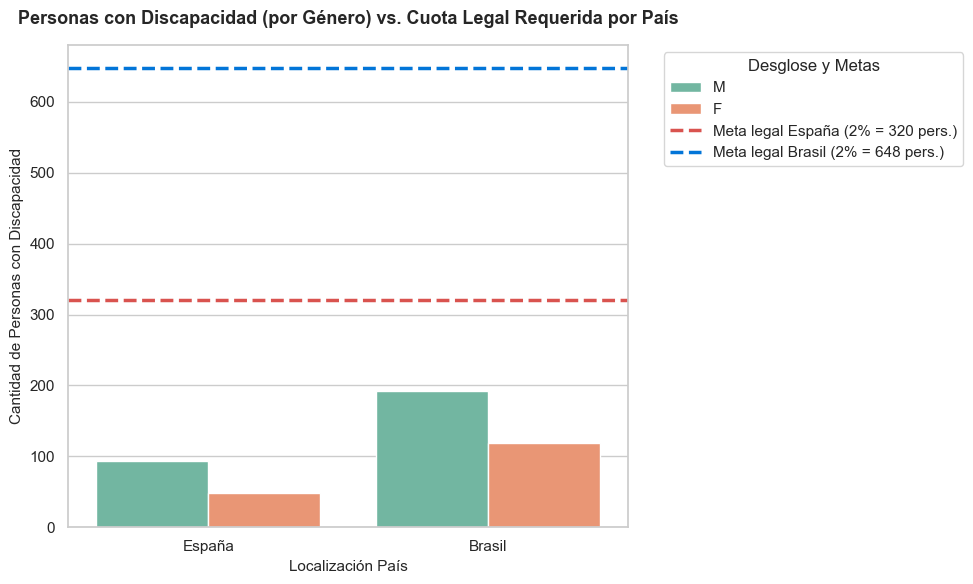

In [97]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. PLANTILLA TOTAL POR PAÍS (ejemplo usando tu DataFrame general, ej: df_plantilla_julio)
# Calculamos el total de trabajadores por país
total_empleados_pais = df_plantilla_julio['Localización País'].value_counts()

# 2. PERSONAS CON DISCAPACIDAD (PD) ACTUALES POR PAÍS
pd_actual_pais = PD['Localización País'].value_counts()

# 3. CÁLCULO DE OBJETIVOS LEGALES
# España: 2% fijo sobre su plantilla total en España
# Brasil: escala según tamaño (ej. si están en el tramo del 2% al 5%, aplicamos el % correspondiente, ej: 2% o el que corresponda a su volumen)
objetivo_espana_num = total_empleados_pais.get('España', 0) * 0.02
# Supongamos el % aplicable en Brasil según su tramo (ej. 2% o el que marque su escala de plantilla)
porcentaje_brasil_ley = (
    0.02  # Ajusta este valor (0.02 a 0.05) según el tramo de su plantilla en Brasil
)
objetivo_brasil_num = (
    total_empleados_pais.get('Brasil', 0) * porcentaje_brasil_ley
)

# 4. CÁLCULO DE LA BRECHA (GAP) = Cuota legal requerida - Personas actuales con discapacidad
gap_espana = max(0, objetivo_espana_num - pd_actual_pais.get('España', 0))
gap_brasil = max(0, objetivo_brasil_num - pd_actual_pais.get('Brasil', 0))

print(f'--- DIAGNÓSTICO DE CUMPLIMIENTO LISMI / LGD & LEY BRASILEÑA ---')
print(
    f'ESPAÑA -> Plantilla: {total_empleados_pais.get("España", 0)} | Actual PD: {pd_actual_pais.get("España", 0)} | Faltan (Gap): int(round({gap_espana})) personas'
)
print(
    f'BRASIL -> Plantilla: {total_empleados_pais.get("Brasil", 0)} | Actual PD: {pd_actual_pais.get("Brasil", 0)} | Faltan (Gap): int(round({gap_brasil})) personas\n'
)

# 5. GRÁFICO DE BARRAS CON LÍNEAS DE OBJETIVO LEGAL
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=PD, x='Localización País', hue='Género', palette='Set2')

# Añadimos las líneas horizontales con las metas legales reales de cada país
# Nota: Como el gráfico compara conteos absolutos, las líneas representan el número objetivo de personas (cuota legal en nº de empleados)
plt.axhline(
    y=objetivo_espana_num,
    color='#d9534f',
    linestyle='--',
    linewidth=2.5,
    label=f'Meta legal España (2% = {int(round(objetivo_espana_num))} pers.)',
)
plt.axhline(
    y=objetivo_brasil_num,
    color='#0275d8',
    linestyle='--',
    linewidth=2.5,
    label=(
        f'Meta legal Brasil ({int(porcentaje_brasil_ley*100)}% ='
        f' {int(round(objetivo_brasil_num))} pers.)'
    ),
)

plt.title(
    'Personas con Discapacidad (por Género) vs. Cuota Legal Requerida por País',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Localización País', fontsize=11)
plt.ylabel('Cantidad de Personas con Discapacidad', fontsize=11)
plt.legend(title='Desglose y Metas', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
#2.  Realiza un análisis del tipo de bajas que se han producido durante el mes de Agosto
#por tipo de:
#   puesto de trabajo, 
#   rangos de edad, 
#   género 
#   zona geográfica.